# Fig. 4 — Combined $R_x\beta + R_x\delta$ intervention across the four regimes
Two-dimensional dose landscapes ($d_\beta$ on x, $d_\delta$ on y). In each panel the upper map is tumor reduction $R_N(T)$ and
the lower map leader suppression $S_L(T)=1-x(T)$, both in %. The red square marks the dose pair maximizing
$J = \tfrac12(R_N/100 + S_L)$. A–D: $T=15$ days; E–H: $T=30$ days.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lf_model import *
set_style()

In [2]:
doses = np.linspace(0, 1, 11)
DB, DD = np.meshgrid(doses, doses)          # [d_delta, d_beta]
maps = {}
for T in (15.0, 30.0):
    for name, (b, g) in REGIMES.items():
        r_n, s_l, J, _ = treatment_outcome(b, g, {"beta": DB, "delta": DD}, T=T)
        iy, ix = np.unravel_index(np.argmax(J), J.shape)
        maps[T, name] = (r_n, s_l, (iy, ix))
        print(f"T={T:.0f} {name:20s} best (d_beta, d_delta) = ({doses[ix]:.1f}, {doses[iy]:.1f}): "
              f"R_N = {r_n[iy, ix]:.1f}%, S_L = {s_l[iy, ix]:.2f}, J = {J[iy, ix]:.3f}")

T=15 Snowdrift            best (d_beta, d_delta) = (1.0, 0.5): R_N = 99.3%, S_L = 0.99, J = 0.992
T=15 Harmony              best (d_beta, d_delta) = (1.0, 0.4): R_N = 92.0%, S_L = 0.96, J = 0.940


T=15 Coordination         best (d_beta, d_delta) = (1.0, 0.4): R_N = 94.1%, S_L = 0.96, J = 0.951
T=15 Prisoner's Dilemma   best (d_beta, d_delta) = (1.0, 0.6): R_N = 98.7%, S_L = 0.98, J = 0.984


T=30 Snowdrift            best (d_beta, d_delta) = (1.0, 0.7): R_N = 99.3%, S_L = 1.00, J = 0.995


T=30 Harmony              best (d_beta, d_delta) = (1.0, 0.5): R_N = 97.0%, S_L = 1.00, J = 0.984


T=30 Coordination         best (d_beta, d_delta) = (1.0, 0.5): R_N = 97.7%, S_L = 1.00, J = 0.987


T=30 Prisoner's Dilemma   best (d_beta, d_delta) = (1.0, 0.7): R_N = 99.3%, S_L = 1.00, J = 0.995


Saved ../figures/Fig4_combination_Rbeta_Rdelta_landscapes.png/.pdf


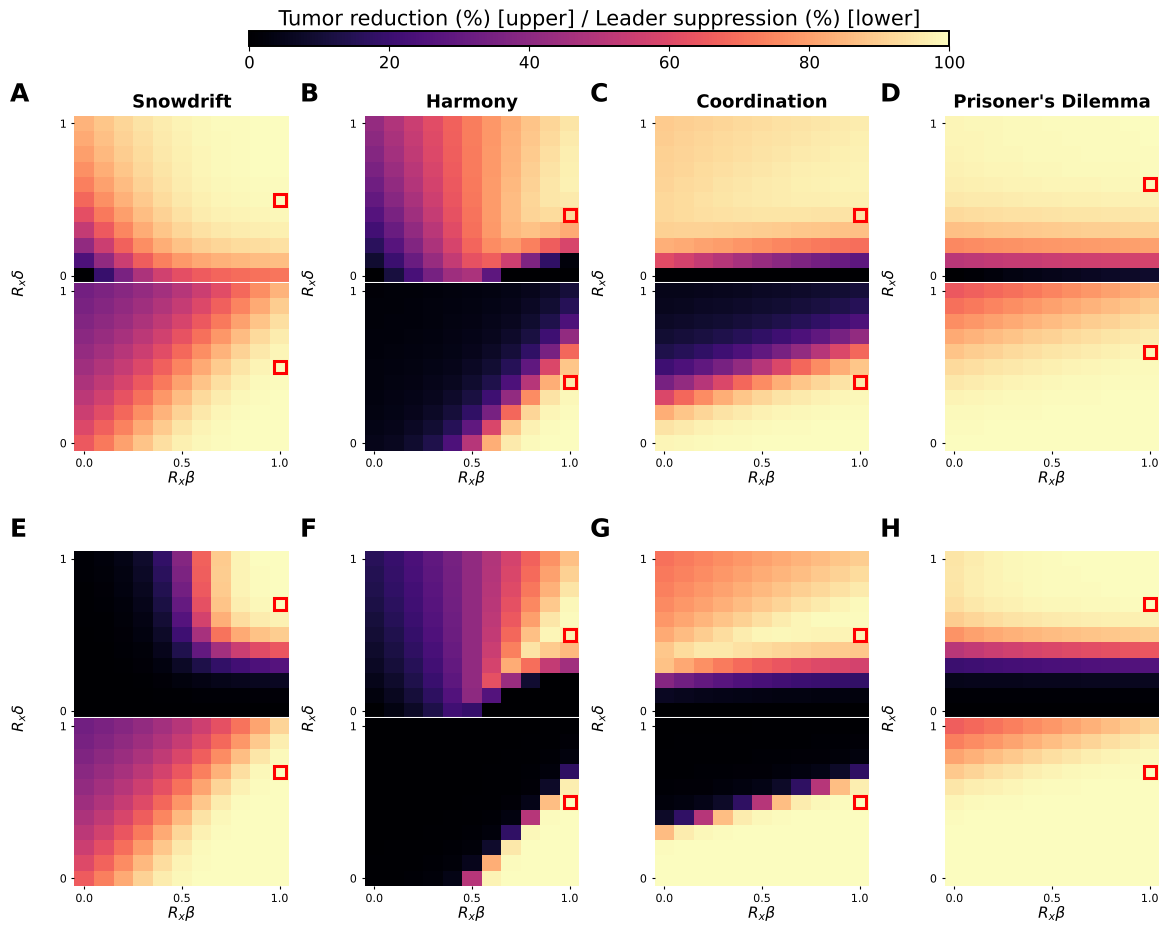

In [3]:
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 4, wspace=0.35, hspace=0.3)
for row, T in enumerate((15.0, 30.0)):
    for j, name in enumerate(REGIME_ORDER):
        r_n, s_l, best = maps[T, name]
        axs, im = composite_heatmap(fig, gs[row, j], r_n, s_l, best, xlabel=r"$R_x\beta$",
                                    ylabel=r"$R_x\delta$", doses=doses)
        if row == 0:
            axs[0].set_title(name, fontweight="bold", fontsize=13)
        panel_letter(axs[0], "ABCDEFGH"[4 * row + j], x=-0.3, y=1.05)
cax = fig.add_axes([0.25, 0.95, 0.5, 0.015])
cb = fig.colorbar(im, cax=cax, orientation="horizontal")
cb.set_label("Tumor reduction (%) [upper] / Leader suppression (%) [lower]")
cax.xaxis.set_label_position("top")
save(fig, "Fig4_combination_Rbeta_Rdelta_landscapes")
plt.show()